# Wildlife Conservation Patrol menggunakan Reinforcement Learning (Q-Learning)

Nama : Sandi Suryo Nugroho

NRP : 5054251020

Link Demo : https://youtu.be/WAxHC9qZ7DY


---

## 1. Introduction

**Wildlife Conservation Patrol** adalah simulasi patroli kawasan konservasi satwa liar berbasis *Reinforcement Learning* (RL). Dalam simulasi ini, satu **patrol agent** bertugas menjelajahi kawasan hutan berbentuk grid 2D untuk memantau titik habitat satwa (`H`) dan menginspeksi titik rawan perburuan liar / *poaching hotspot* (`P`) dengan keterbatasan energi dan jumlah langkah.

Agent tidak diberikan rute terbaik sejak awal. Melalui mekanisme *trial-and-error*, agent mengambil aksi, menerima *reward* atau *penalty* dari environment, lalu memperbarui estimasi nilai aksi pada **Q-Table** hingga terbentuk strategi patroli yang efektif.


- Menggunakan data lingkungan sintetis pada grid 2D berukuran **8 × 8** (bukan peta hutan atau data GPS nyata).
- Hanya terdapat **1 patrol agent** yang bergerak dalam **4 arah** (Up, Down, Left, Right).
- Energi berkurang 1 unit setiap kali agent mengambil langkah; posisi target bersifat statis selama satu episode.
- Kunjungan ke titik *poaching hotspot* merepresentasikan keberhasilan inspeksi/deteksi potensi ancaman (bukan penangkapan pemburu secara dinamis).
- Setiap target cukup dikunjungi satu kali untuk memperoleh *reward* utama.


## 2. Import Library


In [ ]:
from collections import defaultdict
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap

# Konfigurasi tampilan grafik dan tabel agar konsisten & mudah dibaca
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Library berhasil diimpor.")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__}")


Library berhasil diimpor.
NumPy: 2.1.3 | Pandas: 2.2.3


## 3. Environment Configuration

**Ukuran Grid:** 8 × 8 (64 sel)


  - `S`: Starting point (1 titik)
  - `H`: Habitat satwa liar (4 titik)
  - `P`: Poaching hotspot / rawan perburuan liar (4 titik)
  - `F`: Forest / area hutan biasa (sisa 55 sel)

**Batas Sumber Daya:** Energi awal = 40, maksimum langkah = 40

**Skema Reward Awal:**
  - Habitat baru: `+10`
  - Poaching hotspot baru: `+15`
  - Area hutan baru: `+2`
  - Lokasi yang sudah pernah diperiksa: `-2`
  - Gerakan keluar batas peta: `-5`
  - Biaya setiap langkah patroli: `-1`
  - Kehabisan energi sebelum seluruh target (4 habitat + 4 hotspot) selesai diperiksa: `-10`


In [2]:
DEFAULT_CONFIG = {
    "grid_size": 8,
    "num_habitats": 4,
    "num_hotspots": 4,
    "initial_energy": 40,
    "max_steps": 40,
    "seed": 42,
    "rewards": {
        "new_habitat": 10.0,
        "new_hotspot": 15.0,
        "new_forest": 2.0,
        "revisit": -2.0,
        "out_of_bounds": -5.0,
        "step_cost": -1.0,
        "energy_depleted_penalty": -10.0,
    },
}

DEFAULT_RL_PARAMS = {
    "episodes": 2000,       # Ditingkatkan dari target awal 1.000 agar Q-Table bitmask konvergen lebih stabil
    "alpha": 0.1,           # Learning rate
    "gamma": 0.9,           # Discount factor
    "epsilon_start": 1.0,   # Eksplorasi awal
    "epsilon_min": 0.05,    # Batas bawah eksplorasi
    "epsilon_decay": 0.997, # Jadwal penurunan epsilon untuk 2.000 episode
}

print("Konfigurasi Environment:")
for k, v in DEFAULT_CONFIG.items():
    if k != "rewards":
        print(f"  - {k}: {v}")
print("Skema Reward:")
for k, v in DEFAULT_CONFIG["rewards"].items():
    print(f"  - {k}: {v:+.1f}")


Konfigurasi Environment:
  - grid_size: 8
  - num_habitats: 4
  - num_hotspots: 4
  - initial_energy: 40
  - max_steps: 40
  - seed: 42
Skema Reward:
  - new_habitat: +10.0
  - new_hotspot: +15.0
  - new_forest: +2.0
  - revisit: -2.0
  - out_of_bounds: -5.0
  - step_cost: -1.0
  - energy_depleted_penalty: -10.0


## 4. Environment Implementation & Visualization

Kita membangun kelas `WildlifePatrolEnv` yang menangani:
1. **Pembuatan Peta Deterministik (`seed`):** menempatkan Starting Point (`S`), 4 Habitat (`H`), dan 4 Poaching Hotspot (`P`) secara acak terkendali.
2. **Representasi State :**
   Agar agent dapat membedakan apakah target penting sudah dikunjungi atau belum pada posisi yang sama, state dikodekan sebagai tuple:
   $$s = (x, y, \text{energy\_level}, \text{target\_bitmask})$$
   - $(x, y)$: koordinat baris dan kolom agent pada grid 8 × 8.
   - `energy_level`: kategori energi — `2` (*High*: > 60%), `1` (*Medium*: 30%–60%), `0` (*Low*: < 30%).
   - `target_bitmask`: integer 8-bit (`0` s.d. `255`), di mana setiap bit menunjukkan apakah masing-masing dari 4 habitat dan 4 hotspot sudah dikunjungi (`1`) atau belum (`0`).
3. **Fungsi `reset()` dan `step(action)`:** mengelola transisi posisi, pengurangan energi, perhitungan *reward*/*penalty*, dan kondisi terminasi episode (energi habis, langkah mencapai maksimum, atau seluruh 8 target berhasil diperiksa).


Starting Point (S)   : (1, 4)
Habitat Satwa (H)    : [(5, 4), (6, 4), (4, 5), (3, 1)]
Poaching Hotspot (P) : [(5, 3), (0, 5), (7, 3), (0, 4)]

Representasi Teks Grid Awal:
. . . . P P . .
. . . . A . . .
. . . . . . . .
. H . . . . . .
. . . . . H . .
. . . P H . . .
. . . . H . . .
. . . P . . . .


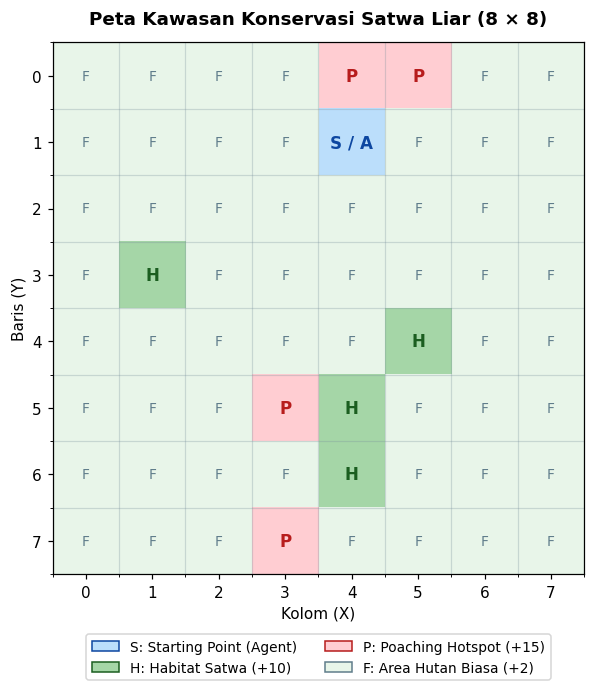

In [3]:
class WildlifePatrolEnv:
    """Simulasi Grid 2D Kawasan Konservasi Satwa Liar untuk Reinforcement Learning."""

    ACTIONS = {
        0: (-1, 0),  # Up
        1: (1, 0),   # Down
        2: (0, -1),  # Left
        3: (0, 1),   # Right
    }
    ACTION_NAMES = {0: "Up", 1: "Down", 2: "Left", 3: "Right"}

    def __init__(self, config=None):
        cfg = DEFAULT_CONFIG if config is None else config
        self.grid_size = cfg["grid_size"]
        self.num_habitats = cfg["num_habitats"]
        self.num_hotspots = cfg["num_hotspots"]
        self.initial_energy = cfg["initial_energy"]
        self.max_steps = cfg["max_steps"]
        self.seed = cfg["seed"]
        self.rewards = dict(cfg["rewards"])

        self._generate_map()
        self.reset()

    def _generate_map(self):
        rng = np.random.default_rng(self.seed)
        all_coords = [
            (r, c) for r in range(self.grid_size) for c in range(self.grid_size)
        ]
        total_special = 1 + self.num_habitats + self.num_hotspots
        chosen_idx = rng.choice(len(all_coords), size=total_special, replace=False)
        chosen_coords = [all_coords[i] for i in chosen_idx]

        self.start_pos = chosen_coords[0]
        self.habitats = chosen_coords[1 : 1 + self.num_habitats]
        self.hotspots = chosen_coords[1 + self.num_habitats :]

        # Daftar seluruh target (4 habitat + 4 hotspot = 8 bit pada bitmask)
        self.targets = self.habitats + self.hotspots
        self.target_to_bit = {pos: idx for idx, pos in enumerate(self.targets)}
        self.all_targets_mask = (1 << len(self.targets)) - 1

        # Matriks simbol peta
        self.base_grid = np.full((self.grid_size, self.grid_size), "F", dtype="<U1")
        self.base_grid[self.start_pos] = "S"
        for pos in self.habitats:
            self.base_grid[pos] = "H"
        for pos in self.hotspots:
            self.base_grid[pos] = "P"

    def _get_energy_category(self):
        ratio = self.energy / self.initial_energy
        if ratio > 0.60:
            return 2  # High (> 60%)
        elif ratio >= 0.30:
            return 1  # Medium (30% - 60%)
        return 0      # Low (< 30%)

    def _get_state(self):
        return (
            self.agent_pos[0],
            self.agent_pos[1],
            self._get_energy_category(),
            self.target_mask,
        )

    def reset(self):
        self.agent_pos = self.start_pos
        self.energy = self.initial_energy
        self.steps = 0
        self.target_mask = 0
        self.visited_cells = {self.start_pos}
        self.visited_habitats = set()
        self.visited_hotspots = set()
        self.trajectory = [self.start_pos]
        self.first_target_order = []  # Menyimpan urutan jenis target ('H'/'P') saat pertama dikunjungi
        return self._get_state()

    def step(self, action):
        self.steps += 1
        self.energy -= 1
        reward = self.rewards["step_cost"]

        dr, dc = self.ACTIONS[action]
        nr, nc = self.agent_pos[0] + dr, self.agent_pos[1] + dc

        # Cek batas grid
        if not (0 <= nr < self.grid_size and 0 <= nc < self.grid_size):
            reward += self.rewards["out_of_bounds"]
            next_pos = self.agent_pos
            event = "out_of_bounds"
        else:
            next_pos = (nr, nc)
            self.agent_pos = next_pos
            cell_type = self.base_grid[next_pos]

            if next_pos in self.visited_cells:
                reward += self.rewards["revisit"]
                event = "revisit"
            else:
                self.visited_cells.add(next_pos)
                if cell_type == "H":
                    reward += self.rewards["new_habitat"]
                    self.visited_habitats.add(next_pos)
                    self.target_mask |= (1 << self.target_to_bit[next_pos])
                    self.first_target_order.append("H")
                    event = "new_habitat"
                elif cell_type == "P":
                    reward += self.rewards["new_hotspot"]
                    self.visited_hotspots.add(next_pos)
                    self.target_mask |= (1 << self.target_to_bit[next_pos])
                    self.first_target_order.append("P")
                    event = "new_hotspot"
                else:
                    reward += self.rewards["new_forest"]
                    event = "new_forest"

        self.trajectory.append(self.agent_pos)

        all_targets_done = (self.target_mask == self.all_targets_mask)
        out_of_energy = (self.energy <= 0)
        max_steps_reached = (self.steps >= self.max_steps)

        done = all_targets_done or out_of_energy or max_steps_reached

        # Penalty jika kehabisan energi sebelum menyelesaikan seluruh target
        if (out_of_energy or max_steps_reached) and not all_targets_done:
            reward += self.rewards["energy_depleted_penalty"]

        info = {
            "event": event,
            "all_targets_done": all_targets_done,
            "habitat_coverage": len(self.visited_habitats) / self.num_habitats * 100.0,
            "hotspot_coverage": len(self.visited_hotspots) / self.num_hotspots * 100.0,
            "unique_visited": len(self.visited_cells),
            "steps": self.steps,
            "remaining_energy": self.energy,
        }
        return self._get_state(), reward, done, info

    def render_text(self):
        grid = self.base_grid.copy()
        for r in range(self.grid_size):
            for c in range(self.grid_size):
                if (r, c) == self.agent_pos:
                    grid[r, c] = "A"
                elif grid[r, c] == "F" and (r, c) not in self.visited_cells:
                    grid[r, c] = "."
        return "\n".join(" ".join(row) for row in grid)


def plot_environment(env, title="Peta Kawasan Konservasi Satwa Liar (8 × 8)", ax=None):
    """Visualisasi peta grid 2D dengan warna dan simbol komponen."""
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(6.8, 6.4))

    color_map = {"F": 0, "S": 1, "H": 2, "P": 3}
    cmap = ListedColormap(["#E8F5E9", "#BBDEFB", "#A5D6A7", "#FFCDD2"])
    numeric_grid = np.vectorize(color_map.get)(env.base_grid)

    ax.imshow(numeric_grid, cmap=cmap, vmin=0, vmax=3)

    # Garis grid
    ax.set_xticks(np.arange(-0.5, env.grid_size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.grid_size, 1), minor=True)
    ax.grid(which="minor", color="#78909C", linestyle="-", linewidth=0.8)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(env.grid_size))
    ax.set_yticks(range(env.grid_size))
    ax.set_xlabel("Kolom (X)")
    ax.set_ylabel("Baris (Y)")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)

    text_colors = {"F": "#607D8B", "S": "#0D47A1", "H": "#1B5E20", "P": "#B71C1C"}
    for r in range(env.grid_size):
        for c in range(env.grid_size):
            sym = env.base_grid[r, c]
            label = "S / A" if (r, c) == env.agent_pos and sym == "S" else sym
            if (r, c) == env.agent_pos and sym != "S":
                label = f"{sym}(A)"
            ax.text(
                c, r, label,
                ha="center", va="center",
                fontsize=11 if sym != "F" else 9,
                fontweight="bold" if sym != "F" else "normal",
                color=text_colors[sym],
            )

    legend_elements = [
        patches.Patch(facecolor="#BBDEFB", edgecolor="#0D47A1", label="S: Starting Point (Agent)"),
        patches.Patch(facecolor="#A5D6A7", edgecolor="#1B5E20", label="H: Habitat Satwa (+10)"),
        patches.Patch(facecolor="#FFCDD2", edgecolor="#B71C1C", label="P: Poaching Hotspot (+15)"),
        patches.Patch(facecolor="#E8F5E9", edgecolor="#607D8B", label="F: Area Hutan Biasa (+2)"),
    ]
    ax.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=True, fontsize=9)

    if created_fig:
        plt.tight_layout()
        plt.show()


# Inisialisasi & tampilkan environment awal
env = WildlifePatrolEnv(DEFAULT_CONFIG)
print(f"Starting Point (S)   : {env.start_pos}")
print(f"Habitat Satwa (H)    : {env.habitats}")
print(f"Poaching Hotspot (P) : {env.hotspots}")
print("\nRepresentasi Teks Grid Awal:")
print(env.render_text())

plot_environment(env)


## 6. Reinforcement Learning Implementation (Q-Learning)

### Komponen Reinforcement Learning
- **State ($s$):** `(row, col, energy_category, target_bitmask)` total ruang state teoritis adalah $8 \times 8 \times 3 \times 2^8 = 49.152$ state
- **Action ($a$):** 4 arah gerak (`0: Up`, `1: Down`, `2: Left`, `3: Right`).
- **Policy ($\pi$):** *Epsilon-Greedy*,  memilih aksi acak dengan probabilitas $\varepsilon$ (*exploration*), dan memilih aksi bernilai Q tertinggi dengan probabilitas $1 - \varepsilon$ (*exploitation*).
- **Pembaruan Q-Value:**
  $$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$


In [4]:
class QLearningAgent:
    """Agen Patroli berbasis Q-Learning dengan Epsilon-Greedy Policy."""

    def __init__(
        self,
        n_actions=4,
        alpha=0.1,
        gamma=0.9,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.997,
        seed=42,
    ):
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.rng = np.random.default_rng(seed)
        self.q_table = defaultdict(lambda: np.zeros(self.n_actions, dtype=np.float64))

    def choose_action(self, state, greedy=False):
        if (not greedy) and (self.rng.random() < self.epsilon):
            return int(self.rng.integers(0, self.n_actions))
        q_values = self.q_table[state]
        max_q = np.max(q_values)
        best_actions = np.flatnonzero(np.isclose(q_values, max_q))
        return int(self.rng.choice(best_actions))

    def update(self, state, action, reward, next_state, done):
        current_q = self.q_table[state][action]
        next_max_q = 0.0 if done else np.max(self.q_table[next_state])
        td_target = reward + self.gamma * next_max_q
        self.q_table[state][action] = current_q + self.alpha * (td_target - current_q)

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


class RandomAgent:
    """Baseline Agent yang memilih aksi secara acak seragam."""

    def __init__(self, n_actions=4, seed=42):
        self.n_actions = n_actions
        self.rng = np.random.default_rng(seed)

    def choose_action(self, state, greedy=False):
        return int(self.rng.integers(0, self.n_actions))


def train_q_learning(env, rl_params=None, seed=42):
    """Melatih QLearningAgent pada env dan mengembalikan agent serta log training."""
    p = DEFAULT_RL_PARAMS if rl_params is None else rl_params
    agent = QLearningAgent(
        n_actions=4,
        alpha=p["alpha"],
        gamma=p["gamma"],
        epsilon_start=p["epsilon_start"],
        epsilon_min=p["epsilon_min"],
        epsilon_decay=p["epsilon_decay"],
        seed=seed,
    )

    history = {
        "episode": [],
        "total_reward": [],
        "habitat_coverage": [],
        "hotspot_coverage": [],
        "unique_visited": [],
        "steps": [],
        "remaining_energy": [],
        "epsilon": [],
        "all_targets_done": [],
    }

    for ep in range(1, p["episodes"] + 1):
        state = env.reset()
        total_reward = 0.0
        done = False

        while not done:
            action = agent.choose_action(state, greedy=False)
            next_state, reward, done, info = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward

        history["episode"].append(ep)
        history["total_reward"].append(total_reward)
        history["habitat_coverage"].append(info["habitat_coverage"])
        history["hotspot_coverage"].append(info["hotspot_coverage"])
        history["unique_visited"].append(info["unique_visited"])
        history["steps"].append(info["steps"])
        history["remaining_energy"].append(info["remaining_energy"])
        history["epsilon"].append(agent.epsilon)
        history["all_targets_done"].append(int(info["all_targets_done"]))

        agent.decay_epsilon()

    return agent, pd.DataFrame(history)

print("Kelas QLearningAgent, RandomAgent, dan fungsi train_q_learning siap digunakan.")


Kelas QLearningAgent, RandomAgent, dan fungsi train_q_learning siap digunakan.


## 8. Agent Training

Kita melatih `QLearningAgent` selama **2.000 episode** pada environment grid 8 × 8 (PRD menetapkan 1.000 episode sebagai target awal yang dapat disesuaikan; dengan ruang state bitmask 8-target, 2.000 episode memberikan keseimbangan lebih baik antara fase eksplorasi dan konvergensi eksploitasi).


In [5]:
trained_agent, train_df = train_q_learning(env, DEFAULT_RL_PARAMS, seed=SEED)

print(f"Training selesai: {len(train_df)} episode")
print(f"Jumlah state unik pada Q-Table: {len(trained_agent.q_table):,}")
print(f"Rata-rata reward 100 episode awal  : {train_df['total_reward'].iloc[:100].mean():.2f}")
print(f"Rata-rata reward 100 episode akhir : {train_df['total_reward'].iloc[-100:].mean():.2f}")
print(f"Rata-rata Habitat Coverage (100 ep akhir) : {train_df['habitat_coverage'].iloc[-100:].mean():.1f}%")
print(f"Rata-rata Hotspot Coverage (100 ep akhir) : {train_df['hotspot_coverage'].iloc[-100:].mean():.1f}%")
print(f"Tingkat penyelesaian semua target (100 ep akhir): {train_df['all_targets_done'].iloc[-100:].mean()*100:.1f}%")


Training selesai: 2000 episode
Jumlah state unik pada Q-Table: 3,262
Rata-rata reward 100 episode awal  : -46.62
Rata-rata reward 100 episode akhir : 102.40
Rata-rata Habitat Coverage (100 ep akhir) : 99.0%
Rata-rata Hotspot Coverage (100 ep akhir) : 99.0%
Tingkat penyelesaian semua target (100 ep akhir): 94.0%


## 9. Training Visualization

Visualisasi berikut memperlihatkan perkembangan pembelajaran agent selama training:
1. **Total Reward per Episode** beserta *moving average* 50 episode untuk melihat tren konvergensi.
2. **Penurunan Epsilon ($\varepsilon$)** yang mengatur transisi dari *exploration* ke *exploitation*.
3. **Habitat Coverage & Hotspot Coverage** selama proses belajar.


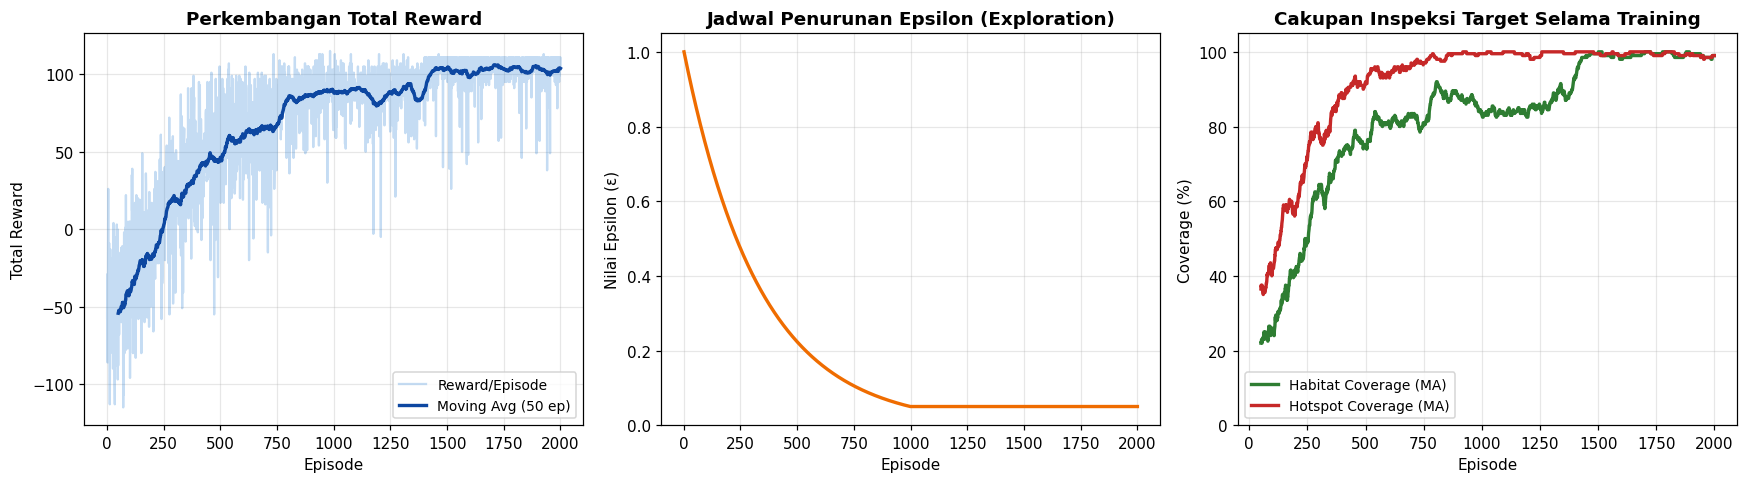

In [6]:
window = 50
train_df["reward_ma"] = train_df["total_reward"].rolling(window).mean()
train_df["habitat_ma"] = train_df["habitat_coverage"].rolling(window).mean()
train_df["hotspot_ma"] = train_df["hotspot_coverage"].rolling(window).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Reward per Episode
axes[0].plot(train_df["episode"], train_df["total_reward"], alpha=0.25, color="#1976D2", label="Reward/Episode")
axes[0].plot(train_df["episode"], train_df["reward_ma"], color="#0D47A1", linewidth=2.2, label=f"Moving Avg ({window} ep)")
axes[0].set_title("Perkembangan Total Reward", fontweight="bold")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total Reward")
axes[0].legend(fontsize=9)

# 2. Epsilon Decay
axes[1].plot(train_df["episode"], train_df["epsilon"], color="#EF6C00", linewidth=2.2)
axes[1].set_title("Jadwal Penurunan Epsilon (Exploration)", fontweight="bold")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Nilai Epsilon (ε)")
axes[1].set_ylim(0, 1.05)

# 3. Habitat & Hotspot Coverage
axes[2].plot(train_df["episode"], train_df["habitat_ma"], color="#2E7D32", linewidth=2.2, label="Habitat Coverage (MA)")
axes[2].plot(train_df["episode"], train_df["hotspot_ma"], color="#C62828", linewidth=2.2, label="Hotspot Coverage (MA)")
axes[2].set_title("Cakupan Inspeksi Target Selama Training", fontweight="bold")
axes[2].set_xlabel("Episode")
axes[2].set_ylabel("Coverage (%)")
axes[2].set_ylim(0, 105)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()


## 10. Patrol Simulation

Setelah training selesai, kita menjalankan agent dengan **greedy policy** (`greedy=True`, tanpa aksi acak) untuk mengamati rute patroli yang telah dipelajari dari titik awal `S` hingga episode berakhir.


Ringkasan Simulasi Greedy Patrol:
  - Total Reward        : 111.0
  - Habitat Coverage    : 100.0%
  - Hotspot Coverage    : 100.0%
  - Unique Area Visited : 31 sel
  - Steps Taken         : 31 langkah
  - Remaining Energy    : 9
  - Urutan Target (H/P) : P -> P -> H -> H -> P -> P -> H -> H
 step action    pos       event  reward  energy
    1     Up (0, 4) new_hotspot    14.0      39
    2  Right (0, 5) new_hotspot    14.0      38
    3  Right (0, 6)  new_forest     1.0      37
    4   Down (1, 6)  new_forest     1.0      36
    5   Down (2, 6)  new_forest     1.0      35
    6   Down (3, 6)  new_forest     1.0      34
    7   Down (4, 6)  new_forest     1.0      33
    8   Left (4, 5) new_habitat     9.0      32
    9   Down (5, 5)  new_forest     1.0      31
   10   Left (5, 4) new_habitat     9.0      30
   11   Left (5, 3) new_hotspot    14.0      29
   12   Down (6, 3)  new_forest     1.0      28
   13   Down (7, 3) new_hotspot    14.0      27
   14   Left (7, 2)  new_forest    

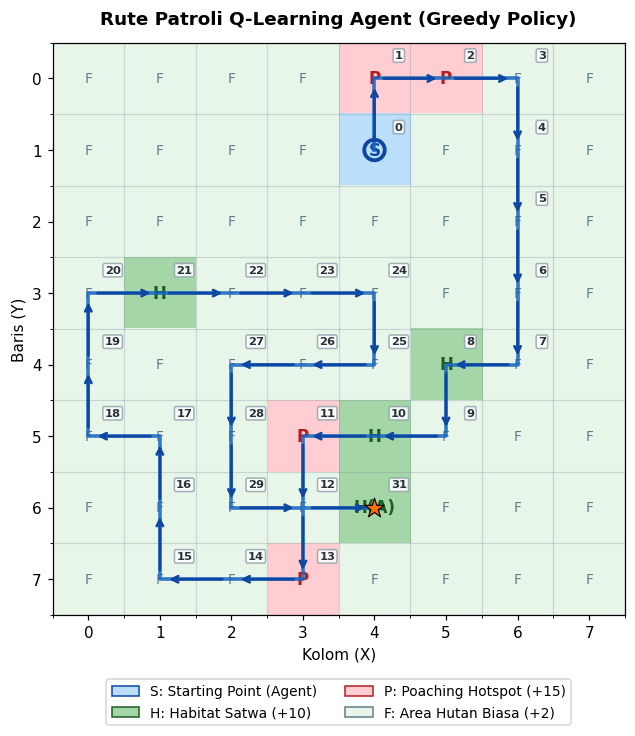

step,action,pos,event,reward,energy
1,Up,"(0, 4)",new_hotspot,14.0,39
2,Right,"(0, 5)",new_hotspot,14.0,38
3,Right,"(0, 6)",new_forest,1.0,37
4,Down,"(1, 6)",new_forest,1.0,36
5,Down,"(2, 6)",new_forest,1.0,35
6,Down,"(3, 6)",new_forest,1.0,34
7,Down,"(4, 6)",new_forest,1.0,33
8,Left,"(4, 5)",new_habitat,9.0,32
9,Down,"(5, 5)",new_forest,1.0,31
10,Left,"(5, 4)",new_habitat,9.0,30


In [7]:
def run_episode(env, agent, greedy=True):
    """Menjalankan satu episode evaluasi dan mencatat lintasan serta metrik."""
    state = env.reset()
    total_reward = 0.0
    done = False
    step_logs = []

    while not done:
        action = agent.choose_action(state, greedy=greedy)
        next_state, reward, done, info = env.step(action)
        total_reward += reward
        step_logs.append({
            "step": info["steps"],
            "action": env.ACTION_NAMES[action],
            "pos": env.agent_pos,
            "event": info["event"],
            "reward": reward,
            "energy": info["remaining_energy"],
        })
        state = next_state

    metrics = {
        "total_reward": total_reward,
        "habitat_coverage": info["habitat_coverage"],
        "hotspot_coverage": info["hotspot_coverage"],
        "unique_visited": info["unique_visited"],
        "steps": info["steps"],
        "remaining_energy": info["remaining_energy"],
        "all_targets_done": int(info["all_targets_done"]),
        "first_target_order": list(env.first_target_order),
        "trajectory": list(env.trajectory),
    }
    return metrics, pd.DataFrame(step_logs)


def plot_patrol_route(env, trajectory, title="Rute Patroli Q-Learning Agent (Greedy Policy)"):
    """Memvisualisasikan rute patroli beserta urutan langkah pada grid 2D."""
    fig, ax = plt.subplots(figsize=(7.2, 6.8))
    plot_environment(env, title=title, ax=ax)

    ys = [p[0] for p in trajectory]
    xs = [p[1] for p in trajectory]

    # Gambar garis lintasan dengan sedikit offset kecil bila melewati sel sama
    ax.plot(xs, ys, color="#1565C0", linewidth=2.4, alpha=0.85, zorder=4)

    # Tambahkan panah arah di setiap segmen
    for i in range(len(trajectory) - 1):
        r1, c1 = trajectory[i]
        r2, c2 = trajectory[i + 1]
        if (r1, c1) != (r2, c2):
            ax.annotate(
                "",
                xy=(c2, r2),
                xytext=(c1, r1),
                arrowprops=dict(arrowstyle="->", color="#0D47A1", lw=1.8, shrinkA=6, shrinkB=6),
                zorder=5,
            )

    # Tandai titik awal & titik akhir
    ax.scatter([xs[0]], [ys[0]], s=180, facecolors="none", edgecolors="#0D47A1", linewidths=2.5, zorder=6)
    ax.scatter([xs[-1]], [ys[-1]], s=180, marker="*", color="#FF6F00", edgecolor="black", linewidths=0.8, zorder=7, label="Posisi Akhir")

    # Nomor urut kunjungan pertama tiap sel di pojok kanan atas sel
    first_visit_step = {}
    for step_idx, pos in enumerate(trajectory):
        if pos not in first_visit_step:
            first_visit_step[pos] = step_idx
    for (r, c), step_idx in first_visit_step.items():
        ax.text(
            c + 0.34, r - 0.32, str(step_idx),
            fontsize=7.5, color="#263238", fontweight="bold",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="#90A4AE", alpha=0.85),
            zorder=8,
        )

    plt.tight_layout()
    plt.show()


sim_metrics, sim_logs = run_episode(env, trained_agent, greedy=True)
print("Ringkasan Simulasi Greedy Patrol:")
print(f"  - Total Reward        : {sim_metrics['total_reward']:.1f}")
print(f"  - Habitat Coverage    : {sim_metrics['habitat_coverage']:.1f}%")
print(f"  - Hotspot Coverage    : {sim_metrics['hotspot_coverage']:.1f}%")
print(f"  - Unique Area Visited : {sim_metrics['unique_visited']} sel")
print(f"  - Steps Taken         : {sim_metrics['steps']} langkah")
print(f"  - Remaining Energy    : {sim_metrics['remaining_energy']}")
print(f"  - Urutan Target (H/P) : {' -> '.join(sim_metrics['first_target_order'])}")

plot_patrol_route(env, sim_metrics["trajectory"])
display(sim_logs.head(15))


## 11. Evaluation & 12. Baseline Comparison 

Untuk mengukur efektivitas strategi Q-Learning secara objektif, kita mengevaluasi kedua agen (**Random Agent** sebagai *baseline* dan **Q-Learning Agent**) selama **100 episode evaluasi** menggunakan enam metrik utama PRD:
1. **Total Reward**
2. **Habitat Coverage (%)**
3. **Hotspot Coverage (%)**
4. **Unique Area Visited**
5. **Steps Taken**
6. **Remaining Energy**


                   Metrik  Random Agent (Mean)  Random Agent (Std)  Q-Learning Agent (Mean)  Q-Learning Agent (Std)
             Total Reward               -56.65               29.06                    111.0                     0.0
     Habitat Coverage (%)                18.50               19.98                    100.0                     0.0
     Hotspot Coverage (%)                34.50               22.13                    100.0                     0.0
Unique Area Visited (sel)                17.04                4.22                     31.0                     0.0
              Steps Taken                40.00                0.00                     31.0                     0.0
         Remaining Energy                 0.00                0.00                      9.0                     0.0
 Semua Target Selesai (%)                 0.00                0.00                    100.0                     0.0


Metrik,Random Agent (Mean),Random Agent (Std),Q-Learning Agent (Mean),Q-Learning Agent (Std)
Total Reward,-56.65,29.06,111.0,0.0
Habitat Coverage (%),18.50,19.98,100.0,0.0
Hotspot Coverage (%),34.50,22.13,100.0,0.0
Unique Area Visited (sel),17.04,4.22,31.0,0.0
Steps Taken,40.00,0.00,31.0,0.0
Remaining Energy,0.00,0.00,9.0,0.0
Semua Target Selesai (%),0.00,0.00,100.0,0.0


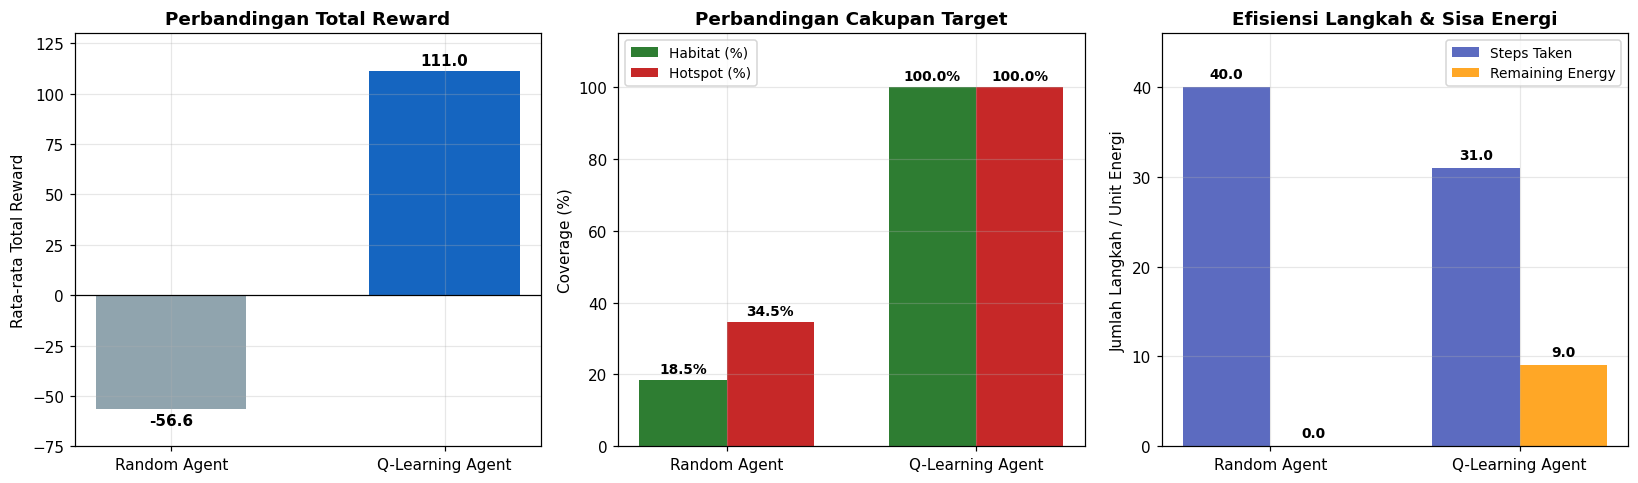

In [8]:
def evaluate_agent(env, agent, n_episodes=100, greedy=True):
    rows = []
    for _ in range(n_episodes):
        m, _ = run_episode(env, agent, greedy=greedy)
        rows.append({
            "total_reward": m["total_reward"],
            "habitat_coverage": m["habitat_coverage"],
            "hotspot_coverage": m["hotspot_coverage"],
            "unique_visited": m["unique_visited"],
            "steps": m["steps"],
            "remaining_energy": m["remaining_energy"],
            "all_targets_done": m["all_targets_done"] * 100.0,
        })
    return pd.DataFrame(rows)


random_agent = RandomAgent(n_actions=4, seed=SEED)
eval_random = evaluate_agent(env, random_agent, n_episodes=100, greedy=False)
eval_qlearn = evaluate_agent(env, trained_agent, n_episodes=100, greedy=True)

comparison_df = pd.DataFrame({
    "Metrik": [
        "Total Reward",
        "Habitat Coverage (%)",
        "Hotspot Coverage (%)",
        "Unique Area Visited (sel)",
        "Steps Taken",
        "Remaining Energy",
        "Semua Target Selesai (%)",
    ],
    "Random Agent (Mean)": [
        eval_random["total_reward"].mean(),
        eval_random["habitat_coverage"].mean(),
        eval_random["hotspot_coverage"].mean(),
        eval_random["unique_visited"].mean(),
        eval_random["steps"].mean(),
        eval_random["remaining_energy"].mean(),
        eval_random["all_targets_done"].mean(),
    ],
    "Random Agent (Std)": [
        eval_random["total_reward"].std(),
        eval_random["habitat_coverage"].std(),
        eval_random["hotspot_coverage"].std(),
        eval_random["unique_visited"].std(),
        eval_random["steps"].std(),
        eval_random["remaining_energy"].std(),
        eval_random["all_targets_done"].std(),
    ],
    "Q-Learning Agent (Mean)": [
        eval_qlearn["total_reward"].mean(),
        eval_qlearn["habitat_coverage"].mean(),
        eval_qlearn["hotspot_coverage"].mean(),
        eval_qlearn["unique_visited"].mean(),
        eval_qlearn["steps"].mean(),
        eval_qlearn["remaining_energy"].mean(),
        eval_qlearn["all_targets_done"].mean(),
    ],
    "Q-Learning Agent (Std)": [
        eval_qlearn["total_reward"].std(),
        eval_qlearn["habitat_coverage"].std(),
        eval_qlearn["hotspot_coverage"].std(),
        eval_qlearn["unique_visited"].std(),
        eval_qlearn["steps"].std(),
        eval_qlearn["remaining_energy"].std(),
        eval_qlearn["all_targets_done"].std(),
    ],
})

display(comparison_df.round(2))

# Visualisasi Perbandingan Performa (Eksperimen 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Grafik 1: Total Reward
agents_lbl = ["Random Agent", "Q-Learning Agent"]
rewards_mean = [eval_random["total_reward"].mean(), eval_qlearn["total_reward"].mean()]
bars0 = axes[0].bar(agents_lbl, rewards_mean, color=["#90A4AE", "#1565C0"], width=0.55)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylim(-75, 130)
axes[0].set_title("Perbandingan Total Reward", fontweight="bold")
axes[0].set_ylabel("Rata-rata Total Reward")
for b in bars0:
    yval = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, yval + (3 if yval >= 0 else -8), f"{yval:.1f}", ha="center", fontweight="bold")

# Grafik 2: Habitat & Hotspot Coverage
x = np.arange(2)
w = 0.35
hab_vals = [eval_random["habitat_coverage"].mean(), eval_qlearn["habitat_coverage"].mean()]
hot_vals = [eval_random["hotspot_coverage"].mean(), eval_qlearn["hotspot_coverage"].mean()]
b1 = axes[1].bar(x - w/2, hab_vals, w, label="Habitat (%)", color="#2E7D32")
b2 = axes[1].bar(x + w/2, hot_vals, w, label="Hotspot (%)", color="#C62828")
axes[1].set_xticks(x)
axes[1].set_xticklabels(agents_lbl)
axes[1].set_ylim(0, 115)
axes[1].set_title("Perbandingan Cakupan Target", fontweight="bold")
axes[1].set_ylabel("Coverage (%)")
axes[1].legend(fontsize=9)
for b in list(b1) + list(b2):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{b.get_height():.1f}%", ha="center", fontsize=9, fontweight="bold")

# Grafik 3: Efisiensi Langkah & Sisa Energi
steps_vals = [eval_random["steps"].mean(), eval_qlearn["steps"].mean()]
energy_vals = [eval_random["remaining_energy"].mean(), eval_qlearn["remaining_energy"].mean()]
b3 = axes[2].bar(x - w/2, steps_vals, w, label="Steps Taken", color="#5C6BC0")
b4 = axes[2].bar(x + w/2, energy_vals, w, label="Remaining Energy", color="#FFA726")
axes[2].set_xticks(x)
axes[2].set_xticklabels(agents_lbl)
axes[2].set_ylim(0, 46)
axes[2].set_title("Efisiensi Langkah & Sisa Energi", fontweight="bold")
axes[2].set_ylabel("Jumlah Langkah / Unit Energi")
axes[2].legend(fontsize=9)
for b in list(b3) + list(b4):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.1f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 12. Kesimpulan


   **Eksperimen Random Agent vs Q-Learning Agent (100 Episode Evaluasi):**
   - **Random Agent** hanya mencapai rata-rata total reward **-56,65** (std 29,06) dengan cakupan **18,5% habitat** dan **34,5% hotspot**, selalu menghabiskan seluruh **40 langkah** (sisa energi **0**), dan **0%** berhasil menyelesaikan seluruh target.
   - **Q-Learning Agent** meningkatkan performa secara drastis menjadi total reward **+111,00** (std 0,00), **100% habitat coverage**, **100% hotspot coverage**, mengunjungi **31 sel unik** tanpa pengulangan dalam **31 langkah**, dan menyisakan **9 unit energi**.

Simulasi ini membuktikan bahwa **Q-Learning dengan representasi state berbasis bitmask** mampu mempelajari strategi patroli konservasi secara mandiri tanpa diberikan rute awal, mengungguli patroli acak pada seluruh metrik evaluasi di berbagai konfigurasi peta. Untuk pengembangan berikutnya, simulasi dapat diperluas ke **Deep Q-Network (DQN)** agar dapat menangani peta berukuran lebih besar, target bergerak dinamis (satwa/pemburu), atau multi-agent patroli.
